# 二重振り子

2自由度の運動方程式をSciPyで解き、質点の軌跡とアニメーションを表示します。角度は鉛直下向きから測ります。

質点の位置は
$$
(x_1,y_1)=(l_1\sin\theta_1,-l_1\cos\theta_1),\quad
(x_2,y_2)=(l_1\sin\theta_1+l_2\sin\theta_2,
-l_1\cos\theta_1-l_2\cos\theta_2).
$$
Euler--Lagrange方程式を $\ddot\theta_1,\ddot\theta_2$ についての2元連立一次方程式として解きます。質量行列を直接解くため、余分な成分除算による見かけの特異点を作りません。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML
from scipy.integrate import solve_ivp

g = 9.81
l1, l2 = 0.4, 0.4
m1, m2 = 1.0, 1.0

def double_pendulum_rhs(t, state, l1, l2, m1, m2, g):
    theta1, theta2, omega1, omega2 = state
    delta = theta1 - theta2
    matrix = np.array([
        [(m1 + m2) * l1, m2 * l2 * np.cos(delta)],
        [m2 * l1 * np.cos(delta), m2 * l2],
    ])
    rhs = np.array([
        -m2 * l2 * omega2**2 * np.sin(delta)
        - (m1 + m2) * g * np.sin(theta1),
        m2 * l1 * omega1**2 * np.sin(delta)
        - m2 * g * np.sin(theta2),
    ])
    alpha1, alpha2 = np.linalg.solve(matrix, rhs)
    return [omega1, omega2, alpha1, alpha2]

def positions(theta1, theta2):
    p1 = np.array([l1 * np.sin(theta1), -l1 * np.cos(theta1)])
    p2 = p1 + np.array([l2 * np.sin(theta2), -l2 * np.cos(theta2)])
    return p1, p2

def mechanical_energy(states):
    theta1, theta2, omega1, omega2 = states
    kinetic = (
        0.5 * (m1 + m2) * l1**2 * omega1**2
        + 0.5 * m2 * l2**2 * omega2**2
        + m2 * l1 * l2 * omega1 * omega2 * np.cos(theta1 - theta2)
    )
    potential = (
        -(m1 + m2) * g * l1 * np.cos(theta1)
        - m2 * g * l2 * np.cos(theta2)
    )
    return kinetic + potential


In [2]:
assert np.allclose(
    double_pendulum_rhs(0.0, np.zeros(4), l1, l2, m1, m2, g),
    np.zeros(4)
)
theta1_0 = np.pi / 2
theta2_0 = np.pi / 2
omega1_0 = omega2_0 = 0.0
initial_state = np.array([theta1_0, theta2_0, omega1_0, omega2_0])

t0, t_end = 0.0, 10.0
time_points = np.linspace(t0, t_end, 1001)
solution = solve_ivp(
    double_pendulum_rhs, (t0, t_end), initial_state,
    args=(l1, l2, m1, m2, g), t_eval=time_points,
    rtol=1e-9, atol=1e-11, max_step=0.02
)
assert solution.success
assert np.isfinite(solution.y).all()
energy = mechanical_energy(solution.y)
absolute_energy_variation = np.max(np.abs(energy - energy[0]))
assert absolute_energy_variation < 1e-6
print(f"success={solution.success}")
print(f"max absolute energy variation={absolute_energy_variation:.2e} J")


success=True
max absolute energy variation=1.09e-07 J


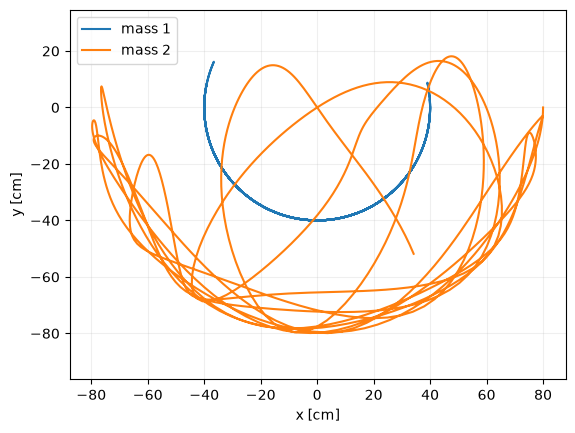

In [3]:
p1 = np.empty((len(time_points), 2))
p2 = np.empty_like(p1)
for i, (theta1, theta2) in enumerate(solution.y[:2].T):
    p1[i], p2[i] = positions(theta1, theta2)

plt.plot(p1[:, 0] * 100, p1[:, 1] * 100, label="mass 1")
plt.plot(p2[:, 0] * 100, p2[:, 1] * 100, label="mass 2")
plt.xlabel("x [cm]")
plt.ylabel("y [cm]")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## アニメーション

計算した有限時間の数値解を表示します。アニメーションは運動の可視化であり、エネルギー保存の厳密な証明ではありません。

In [4]:
fps = 12
frame_indices = np.linspace(0, len(time_points) - 1, 121).astype(int)
fig, ax = plt.subplots(figsize=(4, 4), dpi=70)
ax.set_xlim(-1.1 * (l1 + l2) * 100, 1.1 * (l1 + l2) * 100)
ax.set_ylim(-1.1 * (l1 + l2) * 100, 1.1 * (l1 + l2) * 100)
ax.set_aspect("equal")
ax.set_xlabel("x [cm]")
ax.set_ylabel("y [cm]")
ax.axhline(0, color="0.5", ls="--")
rod1, = ax.plot([], [], color="#245a9b")
rod2, = ax.plot([], [], color="#c53b3b")
point1, = ax.plot([], [], "o", color="#245a9b")
point2, = ax.plot([], [], "o", color="#c53b3b")
title = ax.set_title("")

def update(frame):
    index = frame_indices[frame]
    a, b = p1[index] * 100, p2[index] * 100
    rod1.set_data([0, a[0]], [0, a[1]])
    rod2.set_data([a[0], b[0]], [a[1], b[1]])
    point1.set_data([a[0]], [a[1]])
    point2.set_data([b[0]], [b[1]])
    title.set_text(f"t = {time_points[index]:.2f} s")
    return rod1, rod2, point1, point2, title

pendulum_animation = animation.FuncAnimation(
    fig, update, frames=len(frame_indices),
    interval=1000 / fps, blit=True
)
plt.close(fig)
HTML(pendulum_animation.to_jshtml(fps=fps, default_mode="once"))


### 演習

初期角を少し変えてアニメーションとエネルギーの数値変化を比べます。初期条件に敏感な運動では、有限時間の数値積分だけから長時間後の軌道を予測できないことを確認します。